# NMF with multiple seeds

Run all cells from the repository root or `MF`. Choose the settings below,
check the solver statuses, then compare the figures. Each worker runs all
methods on the same data and starting point for one seed.

Install in the notebook's Python environment if needed:
```python
%pip install numpy scipy matplotlib pandas "joblib>=1.3,<2" threadpoolctl galahad-optrove==5.5.3
```

For `U` of shape `(m, r)` and `V` of shape `(r, n)`, minimize
$$F(U,V)=\tfrac12\|UV-M_{\mathrm{obs}}\|_F^2
 +\tfrac\alpha2(\|U\|_F^2+\|V\|_F^2)
 +\tfrac\beta2(\|(-U)_+\|_F^2+\|(-V)_+\|_F^2).$$
Negative entries are penalized. The data are uniform random factors plus
Gaussian noise; the starting factors are Gaussian.

Reference: [arXiv:2602.08069v1](https://arxiv.org/abs/2602.08069v1),
Section 5.2 / Appendix E.2, Algorithm 1 and subproblem (2). The paper's objective
is equation (28); this notebook uses the weights above. Current settings and
supplementary comparisons differ from the paper, so this is not an exact figure reproduction.

| Paper figure | History quantity |
| --- | --- |
| 3: nonnegativity violation | `penalty` |
| 4: gradient norm | `grad_norm` |
| 6: objective residual | `func` minus the plotting reference |

The plots show common-iteration means, exact/Gauss-Newton comparisons,
a representative seed, and arithmetic means with terminal values retained.
Their aggregation rules are described beside each figure.

All two-panel comparisons call `utils_new.plot_figures` directly.
`prepare_mean_histories` only computes the means and display cutoffs.

In [74]:
import sys
from pathlib import Path
from datetime import datetime

sys.dont_write_bytecode = True
MF_DIR = Path.cwd()
if not (MF_DIR / "oracles_mat_fac.py").exists():
    MF_DIR = MF_DIR / "MF"
sys.path.insert(0, str(MF_DIR.resolve()))

%reload_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import json
from utils_new import plot_figures

from joblib import cpu_count
from joblib.externals.loky import ProcessPoolExecutor
from concurrent.futures import wait, FIRST_COMPLETED
from IPython.display import HTML, display
from time import perf_counter
import importlib.metadata
import platform

%matplotlib inline

# Shared colors from the original multiple-seed figures.
method_colors = {
    "Gradient Method": "#E8601C", "LeAP-SSN": "black",
    "GLAd-SSN, p=0.2": "#9B8AC4", "GLAd-SSN, p=0.4": "#88A5DD",
    "GLAd-SSN, p=0.5": "#8DCBE4", "GLAd-SSN, p=0.6": "#C2E3D2",
    "GLAd-SSN, p=0.8": "#DDECBF", "Cubic Newton (GLRT)": "#A97900",
}

## Settings

- `seeds_to_try`: data and initialization seeds, shared by every method.
- `m, n, r`, `noise`, `alpha, beta`: dimensions, noise and objective weights.
- `initial_factor_std`: Gaussian starting-factor scale.
- `gradient_iterations`, `number_of_iterations`: gradient/Newton update budgets.
- `grad_tol`: absolute gradient-norm stopping tolerance; `None` disables it.
- `initial_lambda`: initial LeAP/GLAd shift; GLAd scales it with `||g||**p`.
- `lss_*`: inexact linear solve; `gn_exponents`: additional Gauss-Newton variants.
- `cubic_*`: [GLRT cubic baseline](CUBIC_SUBPROBLEM.md), independent of `initial_lambda`.

Every method checks `grad_tol` initially and after accepted updates. `success`
means the gradient target was reached; `iterations_exceeded` means the budget
ran out. Other exits retain their failure status. There is no objective stopping test.
LeAP/GLAd use fresh generalized Hessians; GN variants use approximate curvature.
Cubic uses inexact GLRT solves and accepts `f(x+s) <= f(x)+model_change`, with
cubic term `H_k * ||s||**3 / 6`; rejection doubles `H_k`, acceptance halves it
with floor `1e-5`.

`N_JOBS` is capped by available CPUs and seed count; `THREADS_PER_WORKER`
limits numerical-library threads. Use `N_JOBS=1` for sequential runs.
`plot_threshold` changes the first six plots only. `SAVE_FIGURES=True` exports
those plots and the representative/final-mean figures under `parallel_results/`.

Quick check: `(m, n, r) = (6, 4, 2)`, seeds `[549, 498]`, 20 gradient updates
and 5 Newton updates. These are check settings, not the full experiment.

In [75]:
# Original recorded seeds (uncomment for the 20-seed experiment):
# seeds_to_try = [549, 498, 483, 33, 528, 989, 465, 344, 153, 867,
#                 107, 424, 998, 230, 996, 229, 725, 911, 418, 146]
seeds_to_try = [549, 498, 483, 33, 528, 989]

# Data and objective
m, n, r = 50, 25, 4

noise = 0.2
alpha, beta = 0.01, 500.0
initial_factor_std = 0.05

# Iteration budgets and regularization
gradient_iterations = 8000
number_of_iterations = 2000
grad_tol = 1e-8  # Absolute outer gradient norm; None disables this tolerance.
initial_lambda = 10.0
lss_method = "minres"  # SciPy MINRES; GLRT keeps its compiled GALAHAD backend.
lss_tol = 1e-7
lss_maxiters = 800
gn_exponents = [0.2, 0.5]       # Additional exact/Gauss-Newton comparisons

# Additional nonconvex cubic baseline (independent of initial_lambda)
cubic_initial_H = 10.0
cubic_subproblem_tol = 1e-7  # Model-gradient residual relative to ||g||
cubic_glrt_max_iter = 6000  # Per-trial cap.
cubic_max_backtracks = 120

# Plotting and optional export
plot_threshold = 1e-8
SAVE_FIGURES = False

print("Trying seeds:", seeds_to_try)

# Parallel execution: choose multiple seeds above to use multiple workers.
N_JOBS = 6  # 1 for sequential execution.
THREADS_PER_WORKER = 1
PROGRESS_INTERVAL = 2.0

Trying seeds: [549, 498, 483, 33, 528, 989]


## Run one seed

Each worker draws one data set and starting point, then runs the methods in
order. We keep objective, gradient, penalty and time histories, plus exit
statuses and cubic work counts. Python errors propagate normally.

In [76]:
def run_one_seed(seed, settings, mf_directory, threads=1):
    """Run every method on the same data and starting factors for one seed."""
    import os
    import sys
    from time import perf_counter
    sys.dont_write_bytecode = True
    if mf_directory not in sys.path:
        sys.path.insert(0, mf_directory)
    import numpy as np
    from threadpoolctl import threadpool_limits, threadpool_info
    from methods import gradient_method, mf_gladssn, mf_leapssn, cubic_newton_nonconvex_new
    from oracles_mat_fac import PositiveMatrixFactorization
    from galahad import glrt  # Load native libraries before setting thread limits.

    seed_started = perf_counter()
    with threadpool_limits(limits=threads):
        m, n, r = settings["m"], settings["n"], settings["r"]
        rng = np.random.RandomState(seed)
        U_true = rng.rand(m, r)
        V_true = rng.rand(n, r).T
        M_obs = U_true @ V_true + settings["noise"] * rng.randn(m, n)

        # Preserve the original draw order and the (r, n) layout of V.
        initial_values = settings["initial_factor_std"] * rng.randn(m*r + n*r)
        U_0 = initial_values[:m*r].reshape(m, r)
        V_0 = initial_values[m*r:].reshape(n, r).T
        oracle = PositiveMatrixFactorization(M_obs, r=r, alpha=settings["alpha"], beta=settings["beta"])
        x_0 = oracle.pack(U_0, V_0)

        newton_options = dict(
            n_iters=settings["number_of_iterations"], grad_tol=settings["grad_tol"],
            H_0=settings["initial_lambda"], warnings=False,
            lss_tol=settings["lss_tol"], lss_maxiters=settings["lss_maxiters"],
            lss_method=settings["lss_method"], use_gauss_newton=False,
        )
        methods_to_run = {
            "Gradient Method": (gradient_method, dict(
                max_iter=settings["gradient_iterations"], grad_tol=settings["grad_tol"], warnings=False)),
            "LeAP-SSN": (mf_leapssn, newton_options),
        }
        for p in (0.2, 0.4, 0.5, 0.6, 0.8):
            methods_to_run[f"GLAd-SSN, p={p:g}"] = (mf_gladssn, dict(newton_options, p=p))
        methods_to_run["Cubic Newton (GLRT)"] = (cubic_newton_nonconvex_new, dict(
            n_iters=settings["number_of_iterations"], grad_tol=settings["grad_tol"],
            H_0=settings["cubic_initial_H"], subproblem_tol=settings["cubic_subproblem_tol"],
            glrt_max_iter=settings["cubic_glrt_max_iter"],
            max_backtracks=settings["cubic_max_backtracks"], warnings=False,
        ))
        original_method_names = list(methods_to_run)
        for name in ["LeAP-SSN"] + [f"GLAd-SSN, p={p:g}" for p in settings["gn_exponents"]]:
            solver, options = methods_to_run[name]
            methods_to_run[f"{name} (GN)"] = (solver, dict(options, use_gauss_newton=True))

        histories, statuses, method_seconds = {}, {}, {}
        cubic_diagnostics = {}
        for name, (solver, options) in methods_to_run.items():
            started = perf_counter()
            _, status, history = solver(oracle, x_0, **options)
            method_seconds[name] = perf_counter() - started
            statuses[name] = status
            histories[name] = {key: np.asarray(history[key])
                               for key in ("func", "time", "grad_norm", "penalty")}
            if name == "Cubic Newton (GLRT)":
                cubic_diagnostics = {key: np.asarray(history[key]) for key in (
                    "hess_vec_calls", "glrt_iterations", "glrt_status",
                    "subproblem_relative_residual", "subproblem_calls", "H_k") if key in history}
        return dict(
            seed=int(seed), histories=histories, cubic=cubic_diagnostics,
            statuses=statuses, method_seconds=method_seconds,
            seed_seconds=perf_counter() - seed_started,
            original_method_names=original_method_names, thread_pools=threadpool_info(),
            pid=os.getpid(),
        )

## Run the batch

The progress line shows completed seeds and elapsed time. Interrupting stops
unfinished workers; collected results remain in memory. A completed batch is
required for plotting. Check the solver status table below.

`run_metadata` records settings and the environment. Batch time includes worker
startup and shutdown; per-method wall times include shared CPU load.

In [77]:
batch_complete = False
experiment_config = dict(
    m=m, n=n, r=r, noise=noise, alpha=alpha, beta=beta,
    initial_factor_std=initial_factor_std,
    gradient_iterations=gradient_iterations, number_of_iterations=number_of_iterations,
    grad_tol=grad_tol, initial_lambda=initial_lambda,
    lss_method=lss_method, lss_tol=lss_tol, lss_maxiters=lss_maxiters,
    gn_exponents=list(gn_exponents), cubic_initial_H=cubic_initial_H,
    cubic_subproblem_tol=cubic_subproblem_tol, cubic_glrt_max_iter=cubic_glrt_max_iter,
    cubic_max_backtracks=cubic_max_backtracks,
)
gn_base_names = ["LeAP-SSN"] + [f"GLAd-SSN, p={p:g}" for p in gn_exponents]
plot_keys = ("func", "time", "grad_norm", "penalty")
effective_workers = min(N_JOBS, len(seeds_to_try), max(1, cpu_count() // THREADS_PER_WORKER))
print(f"Using {effective_workers} workers, {THREADS_PER_WORKER} numerical-library thread(s) each.")

run_metadata = dict(
    started_at=datetime.now().astimezone().isoformat(),
    python=platform.python_version(), platform=platform.platform(), processor=platform.processor(),
    packages={name: importlib.metadata.version(name) for name in
              ("numpy", "scipy", "matplotlib", "joblib", "threadpoolctl", "galahad-optrove")},
    precision="float64", seeds=[int(seed) for seed in seeds_to_try],
    configuration=dict(experiment_config), requested_workers=N_JOBS,
    effective_workers=effective_workers, threads_per_worker=THREADS_PER_WORKER, state="running",
)
# Set these before worker imports; threadpoolctl also limits threads during each run.
worker_environment = {name: str(THREADS_PER_WORKER) for name in (
    "OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS",
    "BLIS_NUM_THREADS", "VECLIB_MAXIMUM_THREADS", "NUMEXPR_NUM_THREADS")}
worker_environment["PYTHONDONTWRITEBYTECODE"] = "1"

seed_results = {}
batch_started = perf_counter()
progress = display("Starting seeds...", display_id=True)
executor = ProcessPoolExecutor(max_workers=effective_workers, env=worker_environment)
try:
    pending = {executor.submit(run_one_seed, int(seed), experiment_config,
                               str(MF_DIR.resolve()), THREADS_PER_WORKER): seed
               for seed in seeds_to_try}
    while pending:
        finished, _ = wait(pending, timeout=PROGRESS_INTERVAL, return_when=FIRST_COMPLETED)
        for future in finished:
            seed = pending.pop(future)
            seed_results[seed] = future.result()
        progress.update(f"{len(seed_results)}/{len(seeds_to_try)} seeds complete | "
                        f"Elapsed: {perf_counter() - batch_started:.1f} s")
    batch_complete = True
finally:
    # Keep this cleanup so an interrupt or error cannot leave workers running.
    executor.shutdown(wait=True, kill_workers=not batch_complete)
    batch_elapsed_seconds = perf_counter() - batch_started
    seed_results = {seed: seed_results[seed] for seed in seeds_to_try if seed in seed_results}
    all_seeds_histories = {seed: result["histories"] for seed, result in seed_results.items()}
    all_seeds_cubic_diagnostics = {seed: result["cubic"] for seed, result in seed_results.items()}
    all_seeds_statuses = {seed: result["statuses"] for seed, result in seed_results.items()}
    all_seeds_timing = {seed: {key: result[key] for key in
                             ("method_seconds", "seed_seconds", "thread_pools", "pid")}
                       for seed, result in seed_results.items()}
    run_metadata.update(state="complete" if batch_complete else "stopped",
                        batch_elapsed_seconds=batch_elapsed_seconds,
                        completed_seeds=list(seed_results))
    progress.update(f"{len(seed_results)}/{len(seeds_to_try)} seeds complete | "
                    f"{run_metadata['state']} after {batch_elapsed_seconds:.1f} s")

original_method_names = seed_results[seeds_to_try[0]]["original_method_names"]
print("Outer gradient tolerance:", grad_tol)
print("iterations_exceeded means the budget ran out; check all exit statuses.")
status_table = pd.DataFrame([
    dict(seed=seed, method=name, status=status,
         gradient=all_seeds_histories[seed][name]["grad_norm"][-1],
         seconds=all_seeds_timing[seed]["method_seconds"][name])
    for seed in seeds_to_try for name, status in all_seeds_statuses[seed].items()
])
display(HTML("<details><summary>Solver results and wall times</summary>" +
             status_table.to_html(index=False, float_format=lambda x: f"{x:.3g}") + "</details>"))

Using 6 workers, 1 numerical-library thread(s) each.


'6/6 seeds complete | complete after 64.8 s'

Outer gradient tolerance: 1e-08
iterations_exceeded means the budget ran out; check all exit statuses.


seed,method,status,gradient,seconds
549,Gradient Method,iterations_exceeded,0.0187,2.61
549,LeAP-SSN,"success, 129 iters",1.01e-09,1.27
549,"GLAd-SSN, p=0.2","success, 261 iters",2.17e-09,2.89
549,"GLAd-SSN, p=0.4","success, 218 iters",2.22e-09,2.57
549,"GLAd-SSN, p=0.5","success, 208 iters",2.09e-09,2.2
549,"GLAd-SSN, p=0.6","success, 148 iters",4.63e-10,1.76
549,"GLAd-SSN, p=0.8","success, 231 iters",9.48e-10,2.8
549,Cubic Newton (GLRT),"success, 68 iters",1.83e-09,1.17
549,LeAP-SSN (GN),"numerical_stagnation, 831 iters",7.47e-08,11.8
549,"GLAd-SSN, p=0.2 (GN)","numerical_stagnation, 856 iters",6.41e-08,15.3


## Means over common iterations

Every seed has equal weight. Each method ends at its shortest run. Runtime
plots pair the mean metric with mean time at the same iteration. This differs
from the final mean, which uses a shared runtime grid and retains stopped runs.

In [78]:
assert batch_complete, "Run the complete seed batch before plotting."
averaged_history = {}
for name in all_seeds_histories[seeds_to_try[0]]:
    runs = [all_seeds_histories[seed][name] for seed in seeds_to_try]
    length = min(len(h["func"]) for h in runs)
    averaged_history[name] = {}
    for measure in plot_keys:
        total = np.zeros(length)
        for history in runs:
            total += history[measure][:length]
        averaged_history[name][measure] = total / len(runs)
    print(name, ": averaging all seeds through iteration", length - 1)

Gradient Method : averaging all seeds through iteration 8000
LeAP-SSN : averaging all seeds through iteration 129
GLAd-SSN, p=0.2 : averaging all seeds through iteration 171
GLAd-SSN, p=0.4 : averaging all seeds through iteration 196
GLAd-SSN, p=0.5 : averaging all seeds through iteration 166
GLAd-SSN, p=0.6 : averaging all seeds through iteration 148
GLAd-SSN, p=0.8 : averaging all seeds through iteration 167
Cubic Newton (GLRT) : averaging all seeds through iteration 52
LeAP-SSN (GN) : averaging all seeds through iteration 332
GLAd-SSN, p=0.2 (GN) : averaging all seeds through iteration 427
GLAd-SSN, p=0.5 (GN) : averaging all seeds through iteration 421


## Objective, gradient and penalty

The objective reference is the best observed mean among these methods, not a
known optimum. `plot_threshold` trims objective and gradient curves. Penalty
plots retain zeros and later rebounds, with a linear scale near zero.

In [79]:
histories = {name: averaged_history[name] for name in original_method_names}
line_widths = [2.0] * len(histories)
line_styles = ["-"] * len(histories)
colors = [method_colors[name] for name in histories]
mn_func = min(np.min(history["func"]) for history in histories.values())
figures = {}

Last Mean objective - best observed mean of Gradient Method: 0.016068149959806988
Last Mean objective - best observed mean of LeAP-SSN: 0.020258846785193185
Last Mean objective - best observed mean of GLAd-SSN, p=0.2: 0.012855605943737913
Last Mean objective - best observed mean of GLAd-SSN, p=0.4: 0.0
Last Mean objective - best observed mean of GLAd-SSN, p=0.5: 0.007157730543834617
Last Mean objective - best observed mean of GLAd-SSN, p=0.6: 0.025298710889526177
Last Mean objective - best observed mean of GLAd-SSN, p=0.8: 0.012201422898499459
Last Mean objective - best observed mean of Cubic Newton (GLRT): 0.016779063533153504


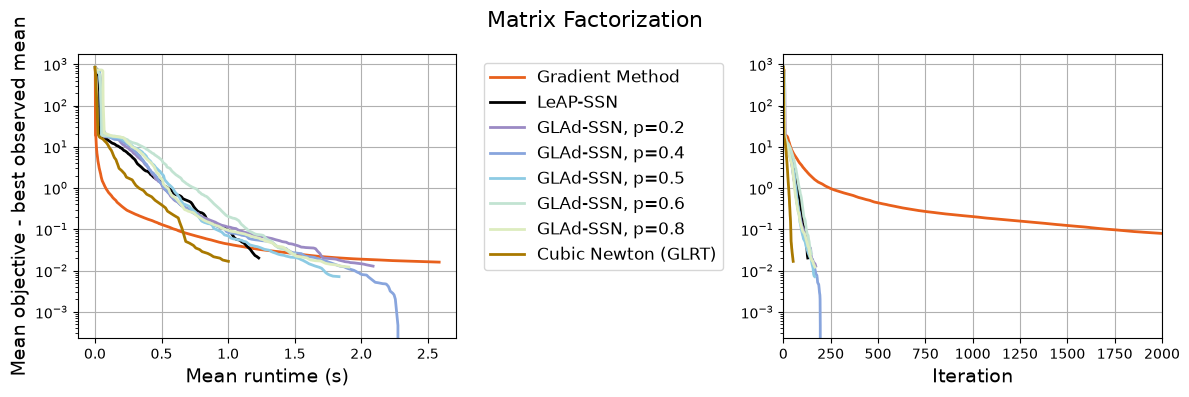

Last Mean gradient norm of Gradient Method: 0.017838031918597952
Last Mean gradient norm of LeAP-SSN: 0.03938894054973558
Last Mean gradient norm of GLAd-SSN, p=0.2: 0.013608185546324647
Last Mean gradient norm of GLAd-SSN, p=0.4: 0.013271200536756978
Last Mean gradient norm of GLAd-SSN, p=0.5: 0.018484774954393917
Last Mean gradient norm of GLAd-SSN, p=0.6: 0.043329752313103716
Last Mean gradient norm of GLAd-SSN, p=0.8: 0.007740908033196644
Last Mean gradient norm of Cubic Newton (GLRT): 0.10937580803511358


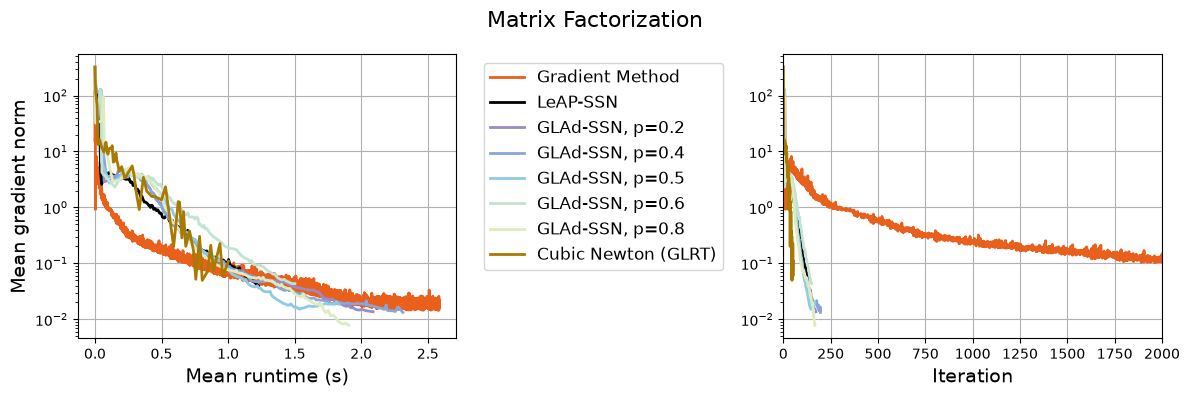

Last Mean penalty of Gradient Method: 0.0010027046245067968
Last Mean penalty of LeAP-SSN: 0.0009347193913061578
Last Mean penalty of GLAd-SSN, p=0.2: 0.001045316823074463
Last Mean penalty of GLAd-SSN, p=0.4: 0.0009002549247987057
Last Mean penalty of GLAd-SSN, p=0.5: 0.0008896009168199359
Last Mean penalty of GLAd-SSN, p=0.6: 0.0009804634788328878
Last Mean penalty of GLAd-SSN, p=0.8: 0.0010326062662225522
Last Mean penalty of Cubic Newton (GLRT): 0.001023147244391809


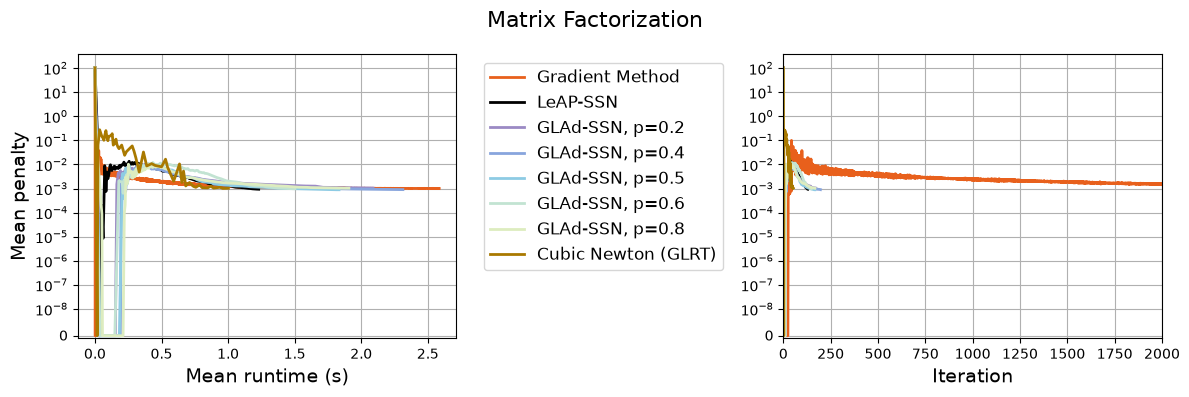

In [80]:
for measure, reference, ylabel in [
    ("func", mn_func, "Mean objective - best observed mean"),
    ("grad_norm", 0, "Mean gradient norm"),
    ("penalty", 0, "Mean penalty"),
]:
    fig = plot_figures(
        list(histories.values()), list(histories.keys()),
        colors=colors, linewidths=line_widths, linestyles=line_styles,
        n=n, m=m, mu_str=None, xlabel="Mean runtime (s)",
        f_star=reference, threshold=plot_threshold,
        suptitle="Matrix Factorization", max_iter=number_of_iterations,
        which_measure_1=measure, which_measure_2=measure, ylabel=ylabel,
    )
    figures[measure] = fig
    plt.show()
    plt.close(fig)

## Exact Hessian and Gauss-Newton

Matching methods share colors; dashed lines use GN curvature. Data and starts
are identical. This comparison uses its own best observed mean objective.

Last Mean objective - best observed mean of Gradient Method: 0.025151104378377198
Last Mean objective - best observed mean of Cubic Newton (GLRT): 0.025862017951723715
Last Mean objective - best observed mean of LeAP-SSN (exact): 0.029341801203763396
Last Mean objective - best observed mean of LeAP-SSN (GN): 0.0039640529349398435
Last Mean objective - best observed mean of GLAd-SSN, p=0.2 (exact): 0.021938560362308124
Last Mean objective - best observed mean of GLAd-SSN, p=0.2 (GN): 0.0021107629392673743
Last Mean objective - best observed mean of GLAd-SSN, p=0.5 (exact): 0.016240684962404828
Last Mean objective - best observed mean of GLAd-SSN, p=0.5 (GN): 0.0


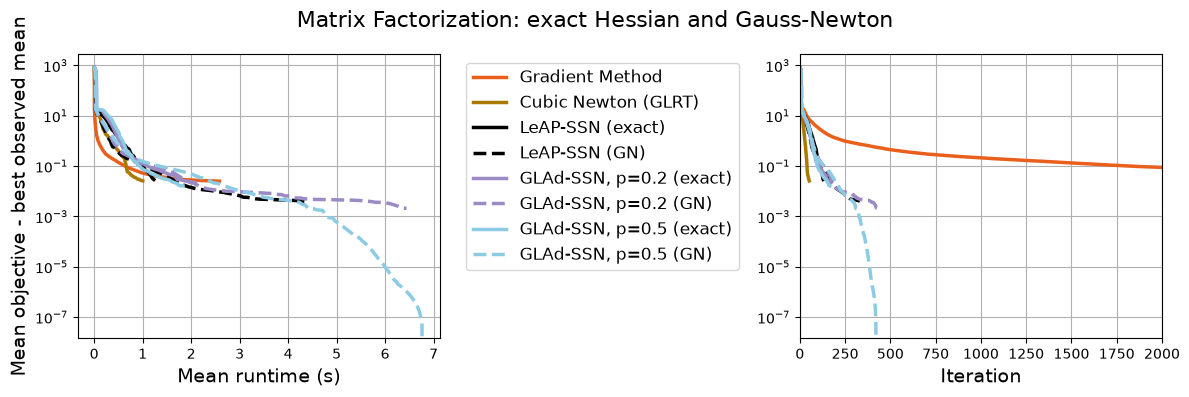

Last Mean gradient norm of Gradient Method: 0.017838031918597952
Last Mean gradient norm of Cubic Newton (GLRT): 0.10937580803511358
Last Mean gradient norm of LeAP-SSN (exact): 0.03938894054973558
Last Mean gradient norm of LeAP-SSN (GN): 0.002251705932689568
Last Mean gradient norm of GLAd-SSN, p=0.2 (exact): 0.013608185546324647
Last Mean gradient norm of GLAd-SSN, p=0.2 (GN): 0.0030181054850820076
Last Mean gradient norm of GLAd-SSN, p=0.5 (exact): 0.018484774954393917
Last Mean gradient norm of GLAd-SSN, p=0.5 (GN): 0.00013361577150834865


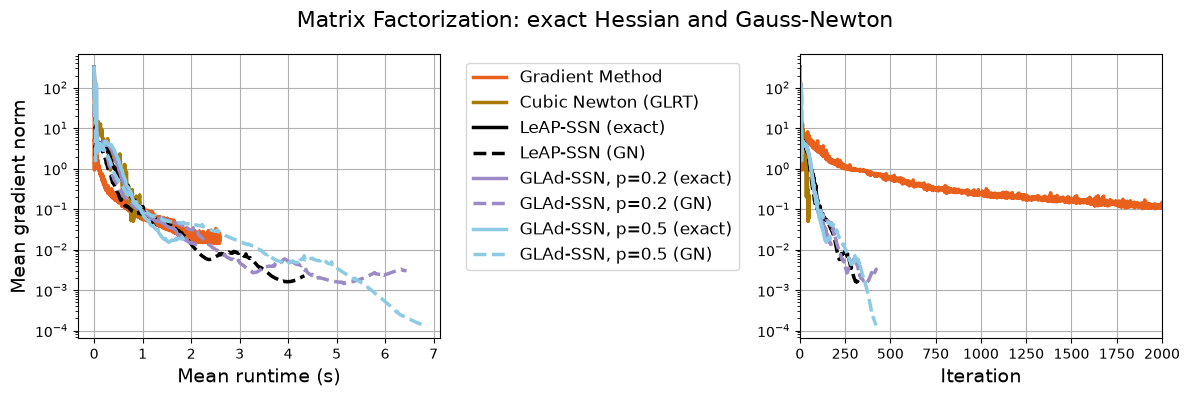

Last Mean penalty of Gradient Method: 0.0010027046245067968
Last Mean penalty of Cubic Newton (GLRT): 0.001023147244391809
Last Mean penalty of LeAP-SSN (exact): 0.0009347193913061578
Last Mean penalty of LeAP-SSN (GN): 0.0008585064413799065
Last Mean penalty of GLAd-SSN, p=0.2 (exact): 0.001045316823074463
Last Mean penalty of GLAd-SSN, p=0.2 (GN): 0.0008422749519185468
Last Mean penalty of GLAd-SSN, p=0.5 (exact): 0.0008896009168199359
Last Mean penalty of GLAd-SSN, p=0.5 (GN): 0.0008267259753942125


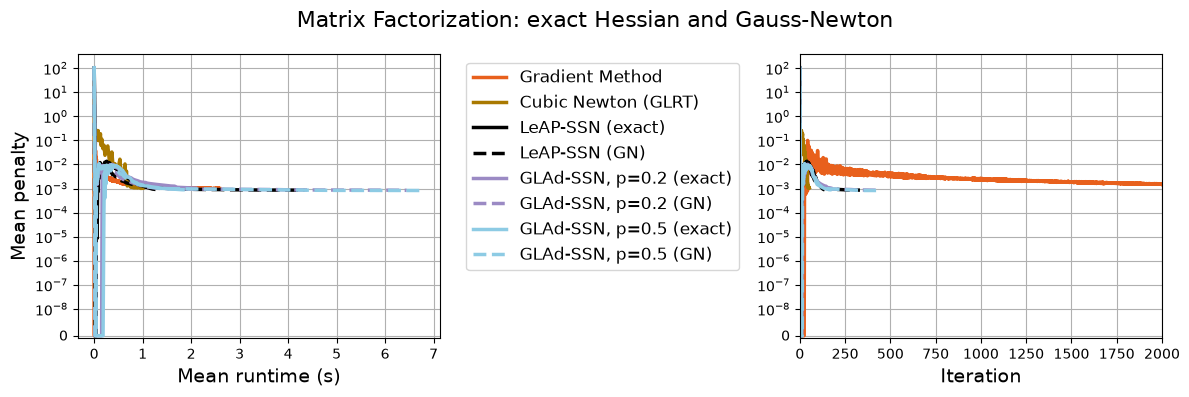

In [81]:
# Select matching exact/Gauss-Newton pairs without changing the original plots.
comparison_names = ["Gradient Method", "Cubic Newton (GLRT)"]
comparison_colors = [colors[0], colors[original_method_names.index("Cubic Newton (GLRT)")]]
comparison_styles = ["-", "-"]
for method_name in gn_base_names:
    color = colors[original_method_names.index(method_name)]
    comparison_names.extend([method_name, f"{method_name} (GN)"])
    comparison_colors.extend([color, color])
    comparison_styles.extend(["-", "--"])

comparison_histories = [averaged_history[name] for name in comparison_names]
comparison_labels = [
    name if name in ("Gradient Method", "Cubic Newton (GLRT)") or name.endswith(" (GN)") else f"{name} (exact)"
    for name in comparison_names
]
comparison_reference = min(np.min(history["func"]) for history in comparison_histories)

for measure, reference, ylabel in [
    ("func", comparison_reference, "Mean objective - best observed mean"),
    ("grad_norm", 0, "Mean gradient norm"),
    ("penalty", 0, "Mean penalty"),
]:
    fig = plot_figures(
        comparison_histories, comparison_labels,
        colors=comparison_colors, linewidths=[2.5] * len(comparison_names),
        linestyles=comparison_styles,
        n=n, m=m, mu_str=None, xlabel="Mean runtime (s)",
        f_star=reference, threshold=plot_threshold,
        suptitle="Matrix Factorization: exact Hessian and Gauss-Newton",
        max_iter=number_of_iterations,
        which_measure_1=measure, which_measure_2=measure, ylabel=ylabel,
    )
    figures[f"{measure}_gn"] = fig
    plt.show()
    plt.close(fig)


## Save the six mean figures

`SAVE_FIGURES=True` saves these PDFs in a new ignored `parallel_results/` folder.
Representative and final-mean plots have their own exports below.

In [82]:
if SAVE_FIGURES:
    output_dir = MF_DIR / "parallel_results" / datetime.now().strftime("%Y%m%d_%H%M%S_%f")
    output_dir.mkdir(parents=True, exist_ok=False)
    for measure, fig in figures.items():
        fig.savefig(output_dir / f"{measure}.pdf", bbox_inches="tight")
    print("Saved figures to", output_dir)

## Representative actual run

One shared seed is selected for every method and metric. It is the **medoid**
of first-hit iteration ranks at fixed gradient targets: unreached targets tie
last, method families and targets have equal weight, and the smallest seed
breaks ties. Runtime does not influence selection. This diagnostic rule does
not guarantee typical penalty behavior; it does not replace the all-seed means.
See [Kaufman and Rousseeuw (1987)](https://wis.kuleuven.be/stat/robust/papers/publications-1987/kaufmanrousseeuw-clusteringbymedoids-l1norm-1987.pdf).

Curves are actual recorded values, with no averaging or extension. Circles mark
endpoints; zeros remain visible. The objective reference is the best observed
value for this seed. The iteration view defaults to 150 updates; `None` shows
all updates. An explicit seed override is labelled an example.

The penalty can return above zero as factor entries change sign; only the total
objective is required to decrease. Its axis is linear below
`representative_penalty_zero_scale` (default `1e-5`), then logarithmic. All values
are retained; this scale is independent of the gradient/objective scale.


In [83]:
from representative_plots import select_representative_seed, target_summary

# Selection settings: one method per family; runtime does not affect selection.
representative_selection_methods = [
    "Gradient Method", "LeAP-SSN", "GLAd-SSN, p=0.5", "Cubic Newton (GLRT)",
]
representative_gradient_targets = [1e2, 1.0, 1e-2, 1e-4, 1e-6, 1e-8]
representative_plot_methods = list(original_method_names)
representative_seed_override = None  # An explicit seed is labelled "example".
comparison_gradient_target = 1e-6     # Reporting target, not the solver grad_tol.
representative_zero_scale = 1e-14
representative_penalty_zero_scale = 1e-5  # Linear near zero; keeps zero-to-positive rebounds.
representative_max_iter = 150          # Display zoom only; None shows the full run.
representative_max_time = None

assert batch_complete, "Run the complete seed batch before plotting."
representative_selection = select_representative_seed(
    all_seeds_histories, representative_selection_methods, representative_gradient_targets)
representative_seed = (representative_selection["seed"] if representative_seed_override is None
                       else int(representative_seed_override))
representative_label = "Representative" if representative_seed_override is None else "Example"
print(f"{representative_label} seed: {representative_seed}")
if representative_seed_override is None and len(representative_selection["tied_seeds"]) > 1:
    print("Tied medoids:", representative_selection["tied_seeds"], "-- using the smallest seed.")
if not representative_selection["informative"]:
    print("The milestone ranks do not distinguish these seeds; there is no unique typical run.")
selection_scores = pd.DataFrame([
    {"seed": seed, "medoid score": score, "shown": seed == representative_seed}
    for seed, score in representative_selection["scores"].items()
])
display(selection_scores.style.format({"medoid score": "{:.4f}"}))

Representative seed: 989


,seed,medoid score,shown
0,33,0.3500,False
1,483,0.3383,False
2,498,0.3017,False
3,528,0.3217,False
4,549,0.2950,False
5,989,0.2733,True


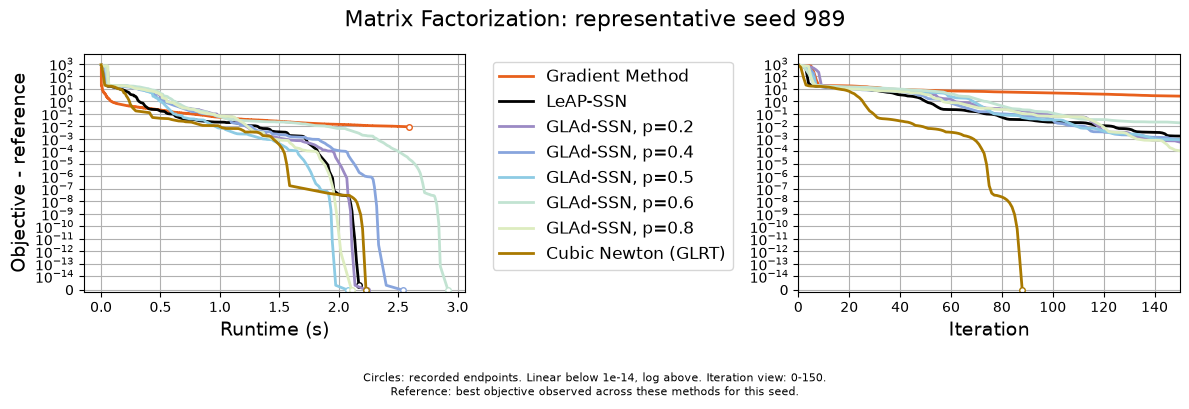

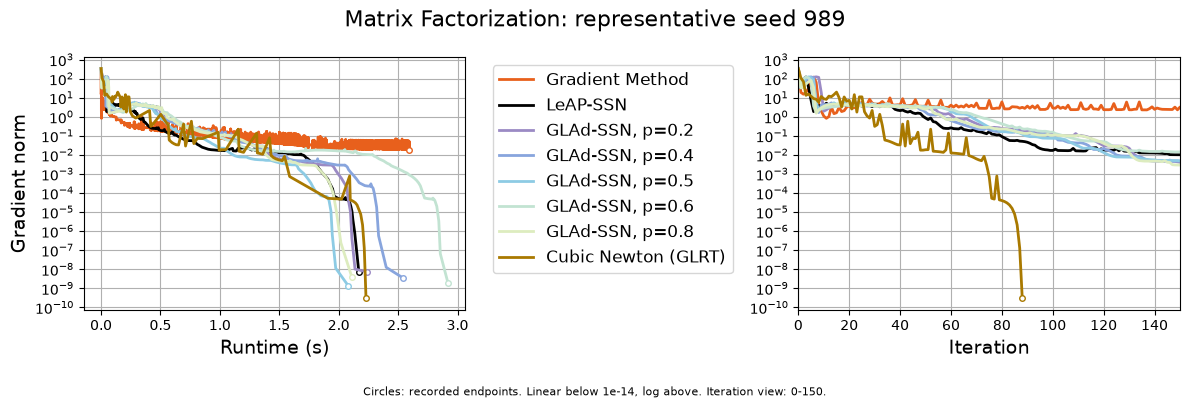

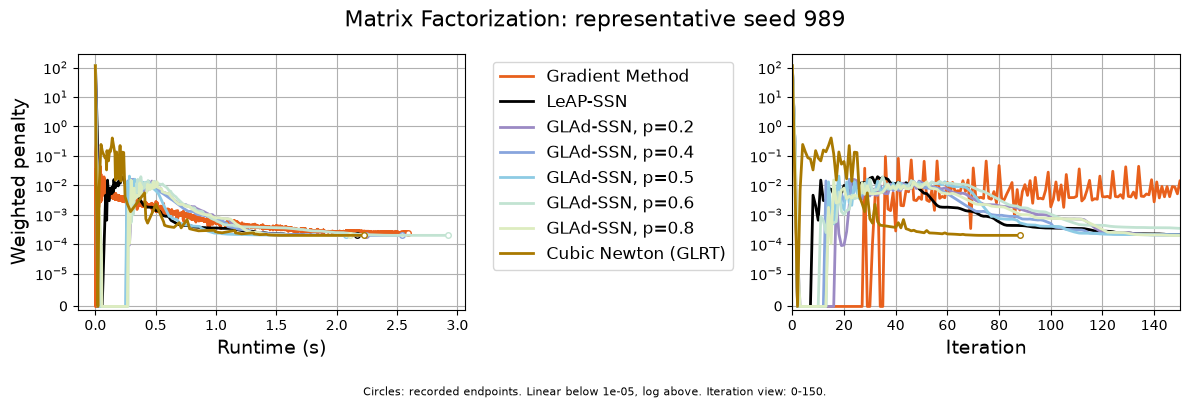

Reporting target: 1e-06; actual solver grad_tol: 1e-08


,method,reached,hit_iteration,hit_time,final_gradient,final_penalty,status
40,Gradient Method,False,--,--,1.901e-02,2.355e-04,iterations_exceeded
41,LeAP-SSN,True,188,2.13,6.788e-09,2.007e-04,"success, 190 iters"
42,"GLAd-SSN, p=0.2",True,178,2.11,7.199e-09,2.007e-04,"success, 180 iters"
43,"GLAd-SSN, p=0.4",True,194,2.34,3.413e-09,2.007e-04,"success, 196 iters"
44,"GLAd-SSN, p=0.5",True,189,1.95,1.383e-09,2.007e-04,"success, 191 iters"
45,"GLAd-SSN, p=0.6",True,245,2.86,1.845e-09,2.007e-04,"success, 246 iters"
46,"GLAd-SSN, p=0.8",True,166,2.02,4.108e-09,2.007e-04,"success, 167 iters"
47,Cubic Newton (GLRT),True,87,2.22,2.983e-10,2.007e-04,"success, 88 iters"


In [84]:
# Same colors as the mean figures; optional GN methods use matching dashed lines.
representative_base_colors = method_colors
representative_styles = {
    name: dict(color=representative_base_colors[name.removesuffix(" (GN)")],
               linestyle="--" if name.endswith(" (GN)") else "-")
    for name in representative_plot_methods
}
representative_histories = {
    name: all_seeds_histories[representative_seed][name] for name in representative_plot_methods
}
representative_reference = min(np.min(h["func"]) for h in representative_histories.values())
representative_figures = {}
for measure, reference, ylabel in [
    ("func", representative_reference, "Objective - reference"),
    ("grad_norm", 0, "Gradient norm"),
    ("penalty", 0, "Weighted penalty"),
]:
    scale = (representative_penalty_zero_scale if measure == "penalty"
             and representative_penalty_zero_scale is not None else representative_zero_scale)
    note = f"Circles: recorded endpoints. Linear below {scale:g}, log above."
    if representative_max_iter is not None:
        note += f" Iteration view: 0-{representative_max_iter:g}."
    if representative_max_time is not None:
        note += f" Runtime view: 0-{representative_max_time:g} s."
    if measure == "func":
        note += "\nReference: best objective observed across these methods for this seed."
    fig = plot_figures(
        list(representative_histories.values()), list(representative_histories),
        colors=[style["color"] for style in representative_styles.values()],
        linewidths=[2.0] * len(representative_histories),
        linestyles=[style["linestyle"] for style in representative_styles.values()],
        n=n, m=m, mu_str=None, xlabel="Runtime (s)",
        f_star=reference, threshold=None, zero_scale=scale,
        max_iter=representative_max_iter, max_time=representative_max_time,
        which_measure_1=measure, which_measure_2=measure, ylabel=ylabel,
        suptitle=f"Matrix Factorization: {representative_label.lower()} seed {representative_seed}",
        sharey=True, mark_endpoints=True, verbose=False, note=note,
    )
    representative_figures[measure] = fig
    display(fig)
    plt.close(fig)

representative_target_rows = target_summary(
    all_seeds_histories, representative_plot_methods,
    comparison_gradient_target, all_seeds_statuses)
representative_target_table = pd.DataFrame(representative_target_rows)
print(f"Reporting target: {comparison_gradient_target:g}; actual solver grad_tol: "
      f"{run_metadata['configuration']['grad_tol']}")
display(representative_target_table.loc[
    representative_target_table.seed == representative_seed,
    ["method", "reached", "hit_iteration", "hit_time", "final_gradient", "final_penalty", "status"],
].style.format({"hit_iteration": "{:.0f}", "hit_time": "{:.3g}",
                "final_gradient": "{:.3e}", "final_penalty": "{:.3e}"}, na_rep="--"))

## Arithmetic mean with terminal values retained

The three figures show objective residual, gradient norm and weighted penalty.
Every seed keeps equal weight, including failures. Stopped runs contribute
their actual final value. Runtime uses the latest observation on a shared time
grid; iterations use matching update counts. No interpolation or log averaging.

For a fixed method and $S$ seeds, let $q_{s,j}$ denote the recorded objective
$F_s(x_{s,j})$, gradient norm $\|\nabla F_s(x_{s,j})\|_2$, or weighted penalty
$P_s(x_{s,j})$. Let $t_{s,j}$ be the runtime and $K_s$ the last recorded
iteration, with the initial point at $j=0$. The means are

$$
\bar q_{\mathrm{iter}}(k)
=\frac{1}{S}\sum_{s=1}^{S}q_{s,\min(k,K_s)},
$$

$$
\bar q_{\mathrm{time}}(t)
=\frac{1}{S}\sum_{s=1}^{S}q_{s,j_s(t)},
\qquad
j_s(t)=\max\{j\in\{0,\ldots,K_s\}:t_{s,j}\le t\}.
$$

The shared time grid starts after every run has its first observation.
After seed $s$ ends, it contributes $q_{s,K_s}$; the denominator stays $S$.
For gradients this averages **norms**, not gradient vectors.

The objective panels display $\bar F-F_{\mathrm{ref}}$, where $F_{\mathrm{ref}}$
is the smallest recorded arithmetic mean across all plotted methods and both
grids, not a known optimum. Its axis is linear below
`mean_objective_zero_scale` (default `1e-8`), then logarithmic. Objective and
penalty curves end at each method's last recording. Penalty zeros and later rebounds are retained; its axis is
linear below `mean_penalty_zero_scale` (default `1e-5`), then logarithmic.

Gradient curves keep the existing cutoff: all seeds at or below
`mean_gradient_target`, otherwise the last recording. Terminal gradient plateaus
within 0.1% of each seed's final norm are hidden; set
`mean_gradient_flat_tail_rtol=None` to disable this display rule. It does not
certify convergence. Missed gradient targets remain listed below.

The gradient target defaults to the completed batch's `grad_tol`. Axis limits
only zoom the view. `arithmetic_mean_summaries` retains the full means and
cutoffs for `func`, `grad_norm` and `penalty`; `mean_gradient_summaries` still
refers to the gradient results. Dashed lines show the recorded GN variants.
`SAVE_FIGURES=True` exports all three PDFs and their numeric summaries.


Not recorded for every seed: GLAd-SSN, p=0.4 (GN), GLAd-SSN, p=0.6 (GN), GLAd-SSN, p=0.8 (GN)
For more GN pairs, include their p values in gn_exponents and rerun the seed batch.


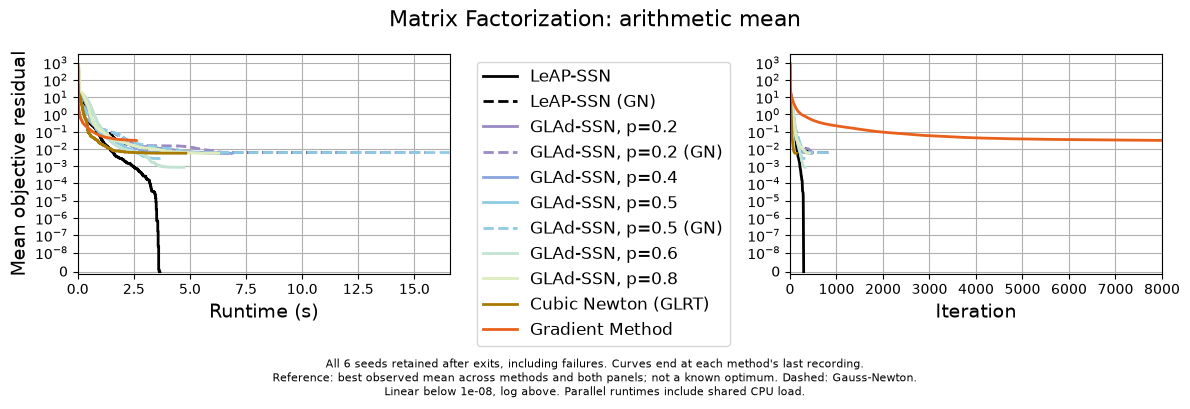

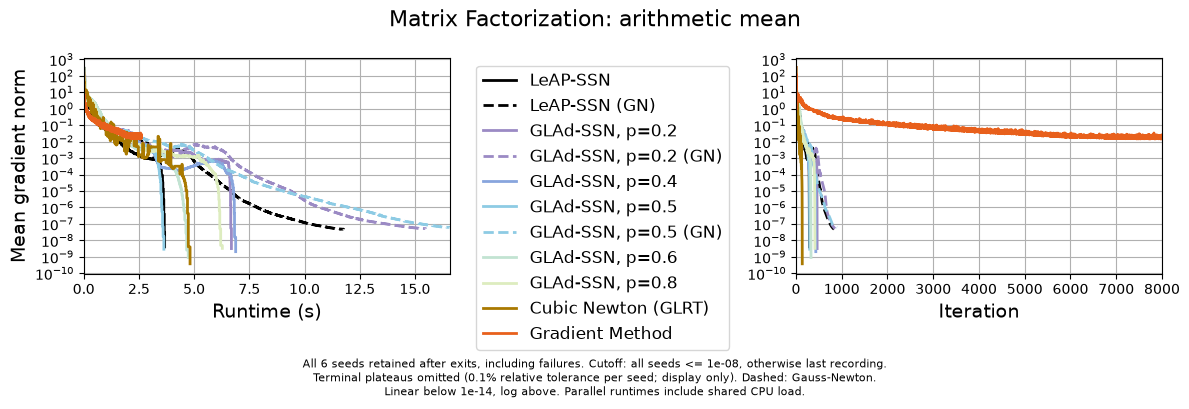

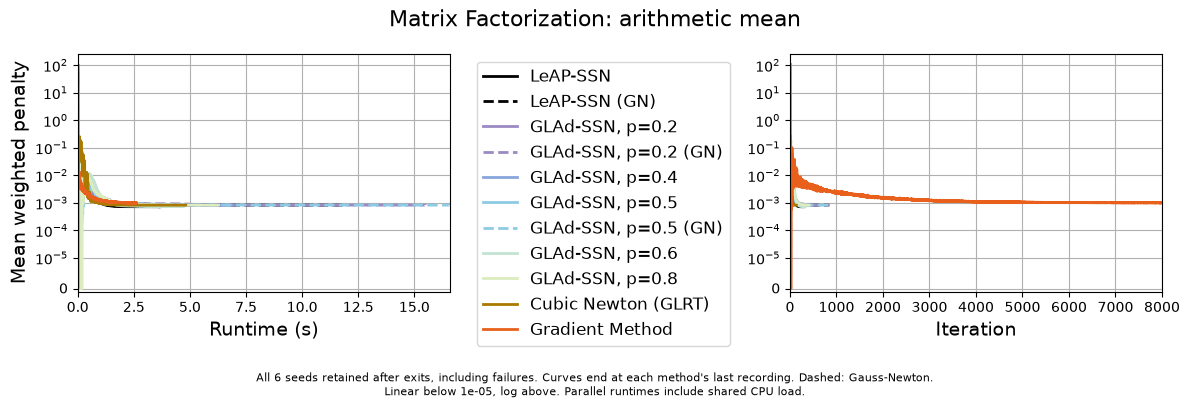

runtime: gradient target missed: LeAP-SSN (GN), GLAd-SSN, p=0.2 (GN), GLAd-SSN, p=0.5 (GN), Gradient Method
iteration: gradient target missed: LeAP-SSN (GN), GLAd-SSN, p=0.2 (GN), GLAd-SSN, p=0.5 (GN), Gradient Method


In [85]:
from utils_new import prepare_mean_histories

assert batch_complete, "Run the complete seed batch before plotting."

# Same color for each exact/Gauss-Newton pair; dashed lines mark GN.
mean_gradient_base_colors = {
    name: method_colors[name] for name in ["LeAP-SSN"]
    + [f"GLAd-SSN, p={p:g}" for p in (0.2, 0.4, 0.5, 0.6, 0.8)]
}
mean_gradient_methods = {}
mean_gradient_missing = []
for base_name, color in mean_gradient_base_colors.items():
    for suffix in ("", " (GN)"):
        name = base_name + suffix
        if all(name in histories for histories in all_seeds_histories.values()):
            mean_gradient_methods[name] = color
        else:
            mean_gradient_missing.append(name)
mean_gradient_methods.update({"Cubic Newton (GLRT)": "#A97900", "Gradient Method": "#E8601C"})
mean_gradient_linestyles = {
    name: "--" if name.endswith(" (GN)") else "-" for name in mean_gradient_methods
}
if mean_gradient_missing:
    print("Not recorded for every seed:", ", ".join(mean_gradient_missing))
    print("For more GN pairs, include their p values in gn_exponents and rerun the seed batch.")
mean_gradient_target = run_metadata["configuration"]["grad_tol"]  # Display cutoff; solver unchanged.
mean_gradient_flat_tail_rtol = 1e-3  # Hide final plateaus within 0.1%; None disables.
mean_gradient_max_iter = None  # Full displayed range; e.g. 150 for a zoom.
mean_gradient_max_time = None  # Full displayed range; e.g. 200 for a zoom in seconds.

mean_objective_zero_scale = 1e-8  # Objective residual axis only.
mean_penalty_zero_scale = 1e-5  # Penalty axis only; preserve zeros and rebounds.

arithmetic_mean_histories = {}
arithmetic_mean_summaries = {}
for measure in ("func", "grad_norm", "penalty"):
    prepared, summary = prepare_mean_histories(
        all_seeds_histories, mean_gradient_methods, measure=measure,
        target=mean_gradient_target if measure == "grad_norm" else None,
        flat_tail_rtol=mean_gradient_flat_tail_rtol if measure == "grad_norm" else None,
    )
    arithmetic_mean_histories[measure] = prepared
    arithmetic_mean_summaries[measure] = summary

# One observed mean reference, shared by both objective panels and all methods.
mean_objective_reference = min(
    np.min(values) for summary in arithmetic_mean_summaries["func"].values()
    for values in summary["means"].values()
)
arithmetic_mean_figures = {}
for measure, reference, ylabel in [
    ("func", mean_objective_reference, "Mean objective residual"),
    ("grad_norm", 0, "Mean gradient norm"),
    ("penalty", 0, "Mean weighted penalty"),
]:
    prepared = arithmetic_mean_histories[measure]
    summary = arithmetic_mean_summaries[measure]
    limits = {}
    for axis, limit in [("runtime", mean_gradient_max_time), ("iteration", mean_gradient_max_iter)]:
        last_shown = max(e["x"] for e in summary[axis]["endpoints"].values())
        limits[axis] = limit if limit is not None else max(last_shown, 1e-12)
    scale = {"func": mean_objective_zero_scale, "grad_norm": 1e-14,
             "penalty": mean_penalty_zero_scale}[measure]
    note = f"All {len(all_seeds_histories)} seeds retained after exits, including failures. "
    if measure == "grad_norm":
        note += (f"Cutoff: all seeds <= {mean_gradient_target:g}, otherwise last recording."
                 if mean_gradient_target is not None else "Cutoff: each method's last recording.")
        if mean_gradient_flat_tail_rtol is not None:
            note += (f"\nTerminal plateaus omitted ({100 * mean_gradient_flat_tail_rtol:g}% relative tolerance "
                     "per seed; display only).")
    else:
        note += "Curves end at each method's last recording."
        if measure == "func":
            note += "\nReference: best observed mean across methods and both panels; not a known optimum."
    if any(style == "--" for style in mean_gradient_linestyles.values()):
        note += " Dashed: Gauss-Newton."
    note += f"\nLinear below {scale:g}, log above. Parallel runtimes include shared CPU load."
    fig = plot_figures(
        list(prepared.values()), list(mean_gradient_methods),
        colors=list(mean_gradient_methods.values()), linewidths=[2.0] * len(mean_gradient_methods),
        linestyles=[mean_gradient_linestyles[name] for name in mean_gradient_methods],
        n=n, m=m, mu_str=None, xlabel="Runtime (s)",
        f_star=reference, threshold=None, zero_scale=scale,
        max_time=limits["runtime"], max_iter=limits["iteration"],
        which_measure_1="runtime", which_measure_2="iteration", ylabel=ylabel,
        suptitle="Matrix Factorization: arithmetic mean",
        sharey=True, runtime_steps=True, verbose=False, note=note,
    )
    arithmetic_mean_figures[measure] = fig
    display(fig)
    plt.close(fig)

# Keep the existing gradient results available under their previous names.
mean_gradient_histories = arithmetic_mean_histories["grad_norm"]
mean_gradient_summaries = arithmetic_mean_summaries["grad_norm"]
mean_gradient_figure = arithmetic_mean_figures["grad_norm"]
for axis, summary in mean_gradient_summaries.items():
    missed = [name for name, e in summary["endpoints"].items() if e["all_seeds_reached"] is False]
    trimmed = [name for name, e in summary["endpoints"].items() if e["flat_tail_trimmed"]]
    if missed:
        print(f"{axis}: gradient target missed:", ", ".join(missed))
    if trimmed:
        print(f"{axis}: terminal plateau hidden:", ", ".join(trimmed))

if SAVE_FIGURES:
    mean_output_dir = MF_DIR / "parallel_results" / ("arithmetic_mean_" + datetime.now().strftime("%Y%m%d_%H%M%S_%f"))
    mean_output_dir.mkdir(parents=True, exist_ok=False)
    for measure, filename in [("func", "mean_objective.pdf"), ("grad_norm", "mean_gradient.pdf"),
                              ("penalty", "mean_penalty.pdf")]:
        arithmetic_mean_figures[measure].savefig(mean_output_dir / filename, bbox_inches="tight")
    mean_record = dict(
        convention="All-seed arithmetic means with terminal values held; objective/penalty end at last recording, gradient additionally uses target/plateau cutoffs",
        objective_reference=float(mean_objective_reference),
        gradient_target=mean_gradient_target, gradient_flat_tail_rtol=mean_gradient_flat_tail_rtol,
        zero_scales=dict(func=mean_objective_zero_scale, grad_norm=1e-14, penalty=mean_penalty_zero_scale),
        seeds=list(seeds_to_try), methods=list(mean_gradient_methods),
        linestyles=mean_gradient_linestyles, missing_methods=mean_gradient_missing,
        max_iter=mean_gradient_max_iter, max_time=mean_gradient_max_time,
        run_metadata=run_metadata, statuses=all_seeds_statuses,
        summaries={measure: {
            axis: dict(grid=summary["grid"].tolist(), endpoints=summary["endpoints"],
                       means={name: values.tolist() for name, values in summary["means"].items()})
            for axis, summary in summaries.items()
        } for measure, summaries in arithmetic_mean_summaries.items()},
    )
    (mean_output_dir / "arithmetic_mean.json").write_text(
        json.dumps(mean_record, indent=2, allow_nan=False), encoding="utf-8")
    print("Saved arithmetic mean figures and data to", mean_output_dir)